# AIDA Korean Cohort — CellTypist Dose-Response Experiment

This notebook evaluates how the proportion of **Korean donors** in the reference set
affects cell-type annotation accuracy (macro-F1) on a held-out Korean query cohort,
using [CellTypist](https://www.celltypist.org/) trained on the AIDA atlas.

**Experimental design**
- Query: 20 randomly selected Korean donors (fixed seed = 42)
- Reference: 60 donors total; proportion of same-ethnicity (Korean) donors varies from 0 % to 100 %
- Metric: macro-averaged F1 across all cell types
- Repeats: 10 independent runs per proportion level

In [1]:
# ── Environment setup ──────────────────────────────────────────────────
# Install required packages (only needed on a fresh Colab runtime)
!pip install -q scanpy celltypist
!pip install -q 'pandas==2.2.3'

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set working directory to the AIDA project folder
import os
os.chdir('/content/drive/MyDrive/aida-celltypist-bias')

# Imports
import scanpy as sc
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, classification_report
import celltypist
import scipy.sparse as sp

print('Environment ready.')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
anndata 0.13.4 requires pandas>=2.3, but you have pandas 2.2.3 which is incompatible.
scanpy 1.12.5 requires pandas>=2.3, but you have pandas 2.2.3 which is incompatible.
Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


Environment ready.


## 1. Load AIDA Dataset

The dataset is loaded in **backed mode** so that only the required cells are pulled into memory.

In [2]:
adata = sc.read_h5ad('/content/drive/MyDrive/aida-celltypist-bias/AIDA.h5ad', backed='r')
print(adata)

AnnData object with n_obs × n_vars = 1265624 × 35477 backed at '/content/drive/MyDrive/aida-celltypist-bias/AIDA.h5ad'
    obs: 'reference_genome', 'gene_annotation_version', 'alignment_software', 'intronic_reads_counted', 'library_id', 'assay_ontology_term_id', 'sequenced_fragment', 'cell_number_loaded', 'institute', 'is_primary_data', 'cell_type_ontology_term_id', 'author_cell_type', 'sample_id', 'sample_preservation_method', 'tissue_ontology_term_id', 'development_stage_ontology_term_id', 'sample_collection_method', 'donor_BMI_at_collection', 'tissue_type', 'suspension_derivation_process', 'suspension_enriched_cell_types', 'cell_viability_percentage', 'suspension_uuid', 'suspension_type', 'donor_id', 'self_reported_ethnicity_ontology_term_id', 'donor_living_at_sample_collection', 'disease_ontology_term_id', 'sex_ontology_term_id', 'nCount_RNA', 'nFeature_RNA', 'pMito', 'NODG', 'nUMI', 'Country', 'Annotation_Level1', 'Annotation_Level2', 'Annotation_Level3', 'Annotation_Level4', 'Smo

## 2. Define Query and Reference Donor Pools

- **Query donors** (n = 20): randomly drawn from the Korean cohort (seed = 42, fixed for reproducibility).
- **Korean reference candidates**: remaining Korean donors not in the query set.
- **Other-ethnicity reference pool**: all donors from non-Korean ethnic groups.

In [3]:
n_ref_total = 60  # defined here so Cell 5 can use it
# ── Donor partitioning (seed fixed for reproducibility) ─────────────────
korean_donors = adata.obs[
    adata.obs['self_reported_ethnicity'] == 'Korean'
]['donor_id'].unique()

np.random.seed(42)
query_donors = np.random.choice(korean_donors, size=20, replace=False)
ref_candidate_donors = korean_donors[~np.isin(korean_donors, query_donors)]

# All non-Korean ethnic groups as the alternative reference pool
all_other_donors = adata.obs[
    adata.obs['self_reported_ethnicity'].isin([
        'Singaporean Chinese',
        'Japanese',
        'Thai',
        'Indian',
        'Singaporean Malay',
        'Singaporean Indian'
    ])
]['donor_id'].unique()

print(f'Query donors          : {len(query_donors)}')
print(f'Korean ref candidates: {len(ref_candidate_donors)}')
print(f'Other-ethnicity pool   : {len(all_other_donors)}')

# Auto-compute feasible proportions based on available ref candidates
_n_avail = len(ref_candidate_donors)
proportions = [p for p in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
               if int(n_ref_total * p) <= _n_avail]
print(f'Ref candidates available: {_n_avail}')
print(f'Feasible proportions    : {proportions}')

Query donors          : 20
Korean ref candidates: 145
Other-ethnicity pool   : 454
Ref candidates available: 145
Feasible proportions    : [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


## 3. CellTypist Training and Annotation Function

Each call assembles a reference of `n_ref_total` donors, trains a CellTypist model,
annotates the query, and returns the macro-F1 score.

In [4]:
def run_celltypist(adata, query_donors, other_donors, ref_candidate_donors,
                   korean_proportion, n_ref_total=60):
    """Train CellTypist on a mixed reference and annotate Korean query donors.

    Parameters
    ----------
    korean_proportion : float
        Fraction of the reference composed of Korean donors (0.0 – 1.0).
    n_ref_total : int
        Total number of reference donors.
    """
    n_korean = int(n_ref_total * korean_proportion)
    n_others   = n_ref_total - n_korean

    korean_ref = (
        np.random.choice(ref_candidate_donors, size=n_korean, replace=False)
        if n_korean > 0 else []
    )
    other_ref      = np.random.choice(other_donors, size=n_others, replace=False)
    all_ref_donors = list(korean_ref) + list(other_ref)

    print(f'  Building reference ({len(all_ref_donors)} donors)...')
    ref_adata = adata[adata.obs['donor_id'].isin(all_ref_donors)].to_memory()
    print(f'  Reference loaded   : {ref_adata.n_obs:,} cells')

    sc.pp.highly_variable_genes(ref_adata, n_top_genes=2000)
    ref_adata = ref_adata[:, ref_adata.var['highly_variable']]

    print('  Training CellTypist model...')
    model = celltypist.train(ref_adata, labels='cell_type', n_jobs=-1,
                            with_mean=False, check_expression=False)
    print('  Model trained.')

    query = adata[adata.obs['donor_id'].isin(query_donors)].to_memory()
    query = query[:, ref_adata.var_names].copy()
    if sp.issparse(query.X):
        query.X = query.X.toarray()

    predictions = celltypist.annotate(query, model=model)
    f1 = f1_score(query.obs['cell_type'],
                  predictions.predicted_labels['predicted_labels'],
                  average='macro')
    print(f'  Macro-F1: {f1:.4f}')
    return f1, predictions, query

print('Function ready.')

Function ready.


## 4. Run Full Dose-Response Experiment

> **⚠ WARNING — do NOT re-run Cell 4a.**  
> Results are already saved to `results_full_curve_korean.csv` and `all_reports_korean.json`.
> Re-running will overwrite the saved data.  
> Use **Cell 4b** below to append additional rounds instead.

In [ ]:
# ── Cell 4a — INITIAL RUN (protected) ──────────────────────────────────
raise Exception("Do NOT run this cell — results are already saved.")


import json
from sklearn.metrics import classification_report

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'
os.makedirs(SAVE_DIR, exist_ok=True)
# proportions defined dynamically in Cell 5
n_repeats   = 8
all_results, all_reports = [], []

for i in range(n_repeats):
    print(f'\n=== Round {i + 1} ===')
    for prop in proportions:
        print(f'  Running {prop * 100:.0f}% Korean...')
        f1, predictions, query = run_celltypist(
            adata, query_donors, all_other_donors,
            ref_candidate_donors, korean_proportion=prop, n_ref_total=60
        )
        true_labels = query.obs['cell_type']
        pred_labels = predictions.predicted_labels['predicted_labels']
        report = classification_report(true_labels, pred_labels, output_dict=True)

        all_results.append({'proportion': prop, 'repeat': i, 'f1': f1})
        all_reports.append({'proportion': prop, 'repeat': i, 'report': report})

        # Save incrementally to Google Drive after every run
        pd.DataFrame(all_results).to_csv(
            f'{SAVE_DIR}/results_full_curve_korean.csv', index=False)
        with open(f'{SAVE_DIR}/all_reports_korean.json', 'w') as fh:
            json.dump(all_reports, fh)

df_results = pd.DataFrame(all_results)
print('\nMean macro-F1 by proportion:')
print(df_results.groupby('proportion')['f1'].mean())


=== Round 1 ===
  Running 0% Korean...
  Building reference (60 donors)...
  Reference loaded   : 103,336 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8034
  Running 10% Korean...
  Building reference (60 donors)...
  Reference loaded   : 108,268 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8092
  Running 20% Korean...
  Building reference (60 donors)...
  Reference loaded   : 110,525 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8282
  Running 30% Korean...
  Building reference (60 donors)...
  Reference loaded   : 115,054 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8039
  Running 40% Korean...
  Building reference (60 donors)...
  Reference loaded   : 117,765 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8237
  Running 50% Korean...
  Building reference (60 donors)...
  Reference loaded   : 118,780 cells
  Training CellTypist model...
  Model trained.


... (79 outputs left out)

  Macro-F1: 0.8230
  Running 80% Korean...
  Building reference (60 donors)...
  Reference loaded   : 127,319 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8249
  Running 90% Korean...
  Building reference (60 donors)...
  Reference loaded   : 134,612 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8176
  Running 100% Korean...
  Building reference (60 donors)...
  Reference loaded   : 132,059 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8208

Mean macro-F1 by proportion:
proportion
0.0    0.807614
0.1    0.813751
0.2    0.810703
0.3    0.809406
0.4    0.811294
0.5    0.811052
0.6    0.814317
0.7    0.815838
0.8    0.812900
0.9    0.816341
1.0    0.819125
Name: f1, dtype: float64


## 4b. Resume / Append Additional Rounds

Adjust `n_extra_rounds` and run this cell to extend the experiment without overwriting existing results.

In [ ]:
import json

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'

# Load existing results
with open(f'{SAVE_DIR}/all_reports_korean.json', 'r') as fh:
    all_reports = json.load(fh)
all_results = pd.read_csv(f'{SAVE_DIR}/results_full_curve_korean.csv').to_dict('records')

next_round = int(pd.read_csv(f'{SAVE_DIR}/results_full_curve_korean.csv')['repeat'].max()) + 1
print(f'Completed rounds: {next_round}  |  Resuming from round {next_round + 1}')

# proportions defined dynamically in Cell 5
n_extra_rounds = 8  # ← set the number of additional rounds to run

for i in range(next_round, next_round + n_extra_rounds):
    print(f'\n=== Round {i + 1} ===')
    for prop in proportions:
        print(f'  Running {prop * 100:.0f}% Korean...')
        f1, predictions, query = run_celltypist(
            adata, query_donors, all_other_donors,
            ref_candidate_donors, korean_proportion=prop, n_ref_total=60
        )
        true_labels = query.obs['cell_type']
        pred_labels = predictions.predicted_labels['predicted_labels']
        report = classification_report(true_labels, pred_labels, output_dict=True)

        all_results.append({'proportion': prop, 'repeat': i, 'f1': f1})
        all_reports.append({'proportion': prop, 'repeat': i, 'report': report})

        pd.DataFrame(all_results).to_csv(
            f'{SAVE_DIR}/results_full_curve_korean.csv', index=False)
        with open(f'{SAVE_DIR}/all_reports_korean.json', 'w') as fh:
            json.dump(all_reports, fh)

print('Done.')

Completed rounds: 16  |  Resuming from round 17

=== Round 17 ===
  Running 0% Korean...
  Building reference (60 donors)...
  Reference loaded   : 103,336 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8032
  Running 10% Korean...
  Building reference (60 donors)...
  Reference loaded   : 108,268 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8091
  Running 20% Korean...
  Building reference (60 donors)...
  Reference loaded   : 110,525 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8281
  Running 30% Korean...
  Building reference (60 donors)...
  Reference loaded   : 115,054 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8039
  Running 40% Korean...
  Building reference (60 donors)...
  Reference loaded   : 117,765 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8239
  Running 50% Korean...
  Building reference (60 donors)...
  Reference loaded   : 118,780 cells
  Training CellTypist model...
  Model trained.


... (79 outputs left out)

  Macro-F1: 0.8230
  Running 80% Korean...
  Building reference (60 donors)...
  Reference loaded   : 127,319 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8249
  Running 90% Korean...
  Building reference (60 donors)...
  Reference loaded   : 134,612 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8176
  Running 100% Korean...
  Building reference (60 donors)...
  Reference loaded   : 132,059 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8208
Done.


## 5. Overall Dose-Response Results

Load the saved CSV and print mean macro-F1 for each proportion level.

In [ ]:
SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'

df_results = pd.read_csv(f'{SAVE_DIR}/results_full_curve_korean.csv')
print('Mean macro-F1 by Korean proportion in reference:')
print(df_results.groupby('proportion')['f1'].mean().round(4))

Mean macro-F1 by Korean proportion in reference:
proportion
0.0    0.8076
0.1    0.8138
0.2    0.8108
0.3    0.8094
0.4    0.8114
0.5    0.8111
0.6    0.8143
0.7    0.8158
0.8    0.8131
0.9    0.8167
1.0    0.8191
Name: f1, dtype: float64


## 6. Dose-Response Plot (Overall)

Macro-F1 (mean ± SD across repeats) as a function of Korean donor proportion in the reference.

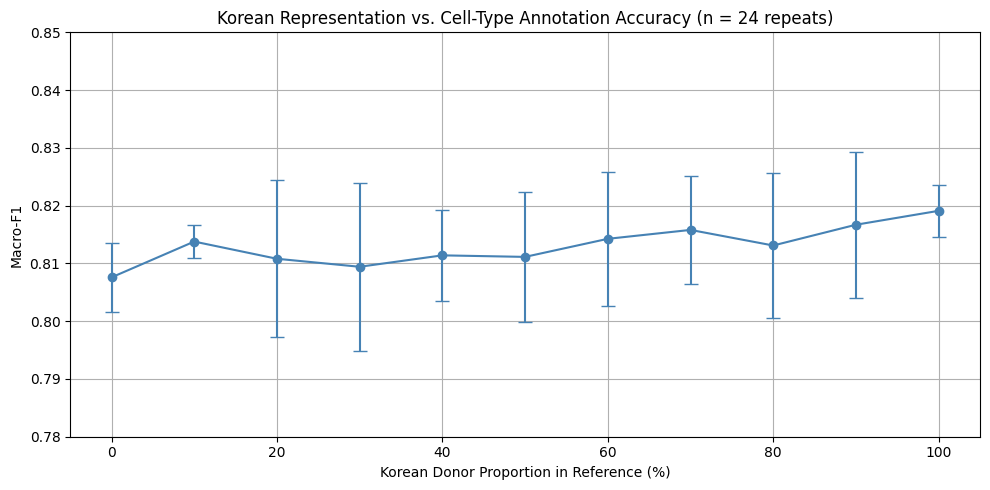

In [ ]:
import matplotlib.pyplot as plt

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'
df_results = pd.read_csv(f'{SAVE_DIR}/results_full_curve_korean.csv')

means = df_results.groupby('proportion')['f1'].mean()
stds  = df_results.groupby('proportion')['f1'].std()
n     = int(df_results['repeat'].max()) + 1

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar([p * 100 for p in means.index], means.values,
            yerr=stds.values, fmt='o-', capsize=5, color='steelblue')
ax.set_xlabel('Korean Donor Proportion in Reference (%)')
ax.set_ylabel('Macro-F1')
ax.set_title(f'Korean Representation vs. Cell-Type Annotation Accuracy (n = {n} repeats)')
ax.set_ylim(0.78, 0.85)
ax.grid(True)
fig.tight_layout()
fig.savefig(f'{SAVE_DIR}/dose_response_final_korean.png', dpi=150)
plt.show()

## 7. Per-Cell-Type Analysis — Rare Cell Types

Cell types with mean query support < 200 cells are treated as rare.
F1 curves are plotted across all proportion levels for each rare type.

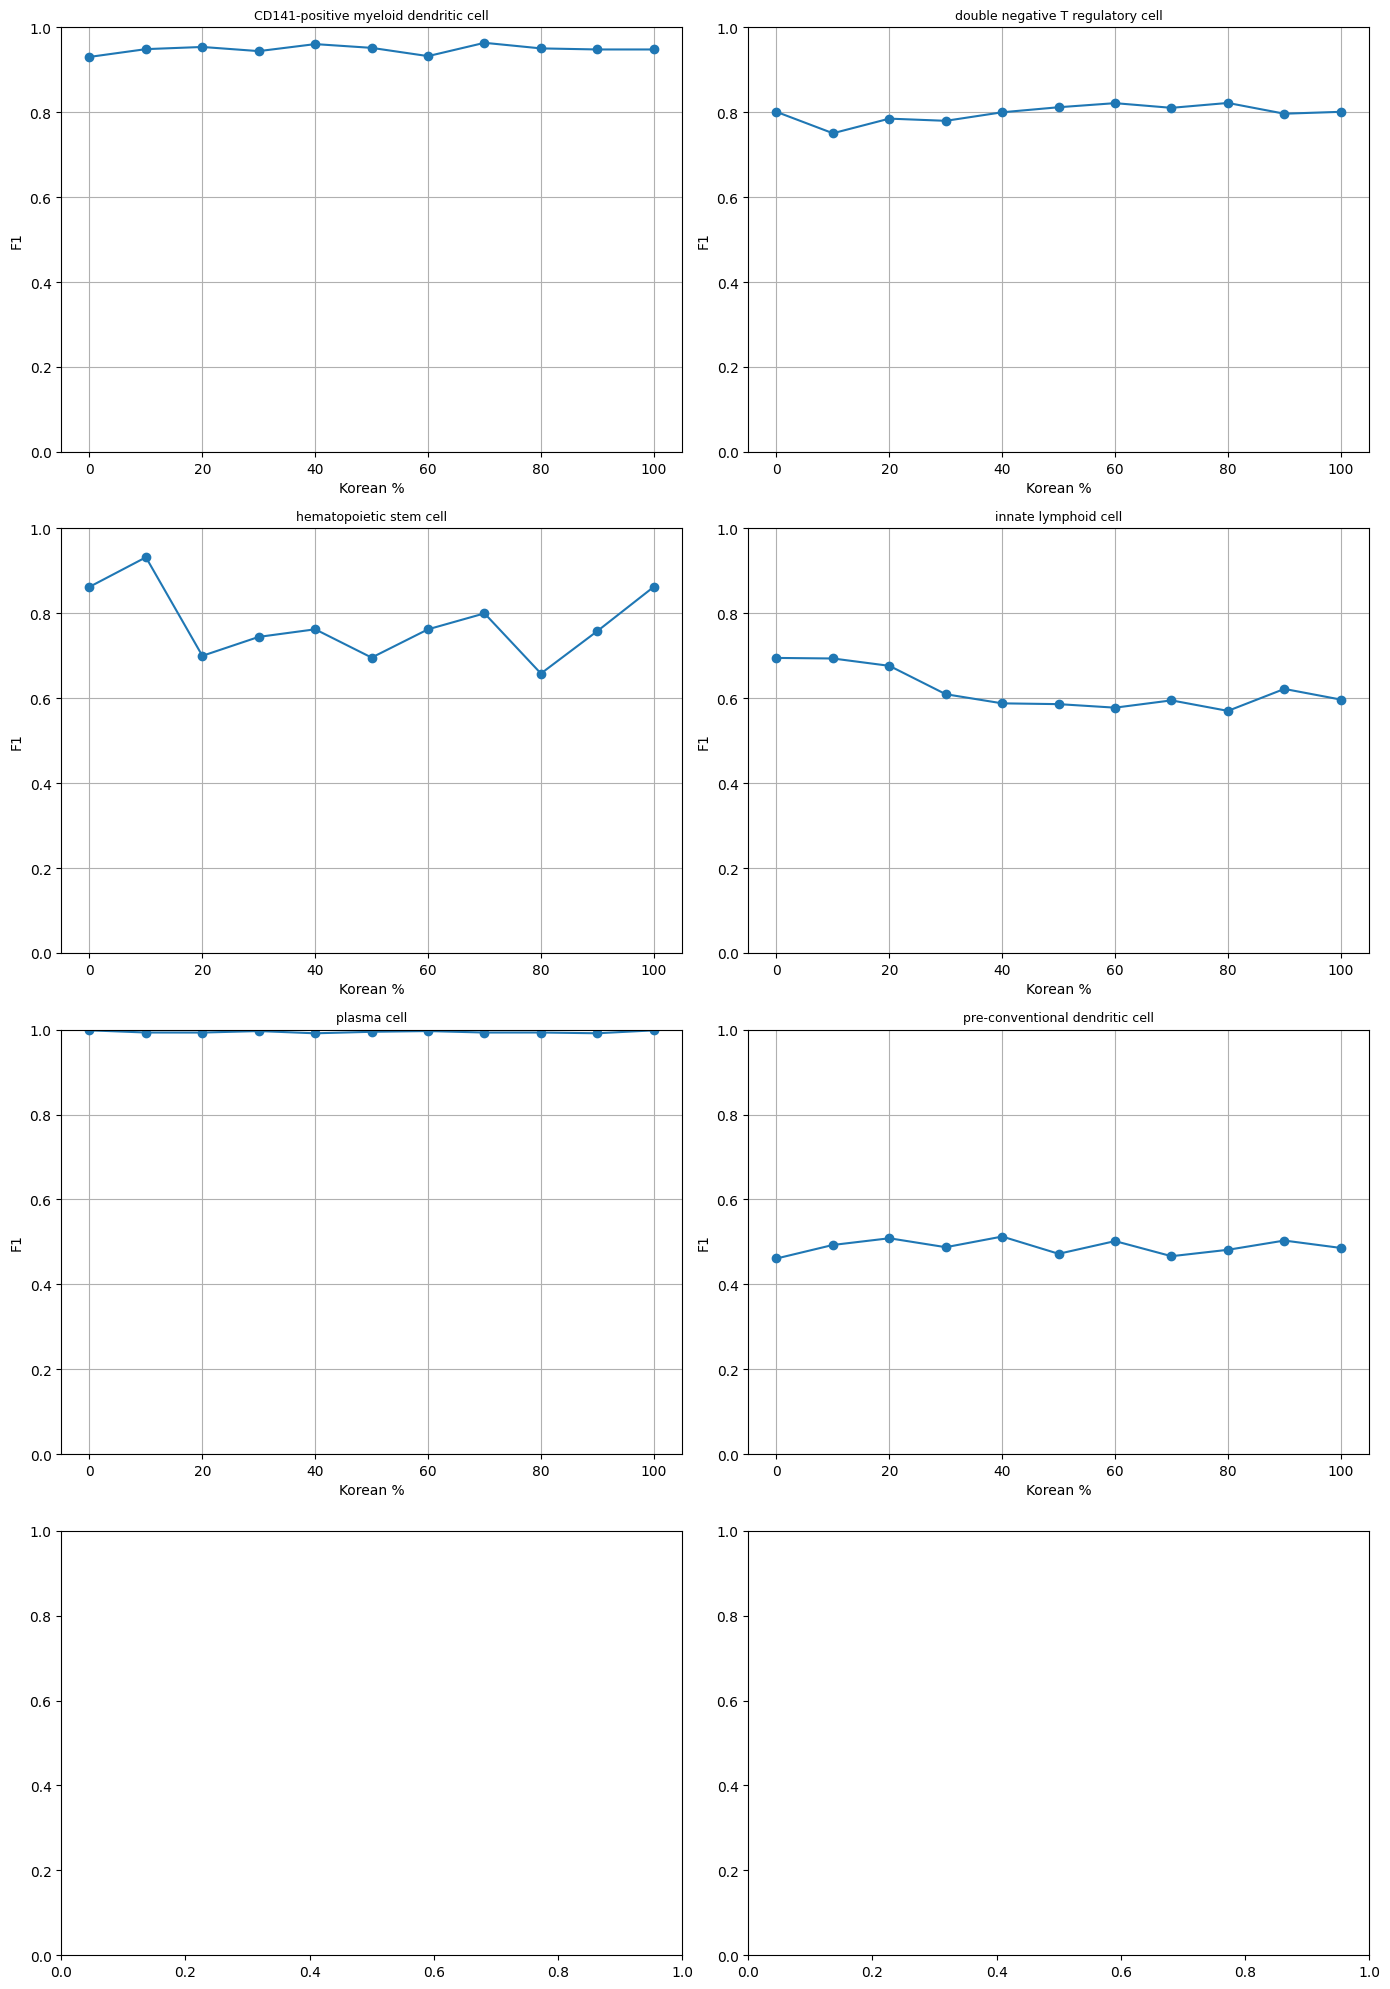

In [ ]:
import json

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'

with open(f'{SAVE_DIR}/all_reports_korean.json', 'r') as fh:
    all_reports = json.load(fh)

# Build per-cell-type F1 table
cell_type_results = []
for entry in all_reports:
    for cell_type, metrics in entry['report'].items():
        if cell_type in ('accuracy', 'macro avg', 'weighted avg'):
            continue
        if isinstance(metrics, dict):
            cell_type_results.append({
                'proportion': entry['proportion'],
                'cell_type' : cell_type,
                'f1'        : metrics['f1-score'],
                'support'   : metrics['support'],
            })

df_cell = pd.DataFrame(cell_type_results)

# Identify rare cell types (mean support < 200)
rare_cells = df_cell.groupby('cell_type')['support'].mean()
rare_cells = rare_cells[rare_cells < 200].index

mean_by_cell = (
    df_cell[df_cell['cell_type'].isin(rare_cells)]
    .groupby(['cell_type', 'proportion'])['f1'].mean().unstack()
)

fig, axes = plt.subplots(len(rare_cells) // 2 + 1, 2, figsize=(14, 20))
axes = axes.flatten()
for idx, ct in enumerate(rare_cells):
    if ct in mean_by_cell.index:
        axes[idx].plot([p * 100 for p in mean_by_cell.columns],
                       mean_by_cell.loc[ct].values, 'o-')
        axes[idx].set_title(ct, fontsize=9)
        axes[idx].set_xlabel('Korean %')
        axes[idx].set_ylabel('F1')
        axes[idx].set_ylim(0, 1)
        axes[idx].grid(True)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/rare_celltypes_curve_korean.png', dpi=150)
plt.show()

## 8. Mean F1 by Cell Type (Full Table)

In [ ]:
import json

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'

with open(f'{SAVE_DIR}/all_reports_korean.json', 'r') as fh:
    all_reports = json.load(fh)

cell_type_results = []
for entry in all_reports:
    for cell_type, metrics in entry['report'].items():
        if cell_type in ('accuracy', 'macro avg', 'weighted avg'):
            continue
        if isinstance(metrics, dict):
            cell_type_results.append({
                'proportion': entry['proportion'],
                'cell_type' : cell_type,
                'f1'        : metrics['f1-score'],
                'support'   : metrics['support'],
            })

df_cell      = pd.DataFrame(cell_type_results)
mean_by_cell = df_cell.groupby(['cell_type', 'proportion'])['f1'].mean().unstack()

print('Mean F1 by cell type across all proportion levels:')
print(mean_by_cell.round(3))

Mean F1 by cell type across all proportion levels:
proportion                                            0.0    0.1    0.2  \
cell_type                                                                 
B cell                                              0.626  0.639  0.661   
CD14-low, CD16-positive monocyte                    0.954  0.957  0.956   
CD14-positive monocyte                              0.961  0.962  0.963   
CD141-positive myeloid dendritic cell               0.930  0.949  0.954   
CD16-negative, CD56-bright natural killer cell,...  0.897  0.889  0.885   
CD16-positive, CD56-dim natural killer cell, human  0.954  0.956  0.958   
CD1c-positive myeloid dendritic cell                0.891  0.893  0.899   
CD4-positive, alpha-beta T cell                     0.290  0.291  0.301   
CD4-positive, alpha-beta cytotoxic T cell           0.788  0.797  0.803   
CD8-positive, alpha-beta T cell                     0.607  0.607  0.622   
CD8-positive, alpha-beta cytotoxic T cell        

## 9. Identify Cell Types Most Sensitive to Korean Proportion

Cell types with |F1(100%) − F1(0%)| > 0.03 are selected for detailed analysis.

In [ ]:
# F1 difference: 100% Korean reference vs. 0% Korean reference
diff = mean_by_cell[1.0] - mean_by_cell[0.0]
diff = diff.sort_values()

print('F1 difference (100% Korean − 0% Korean):')
print(diff.round(3))

F1 difference (100% Korean − 0% Korean):
cell_type
innate lymphoid cell                                    -0.098
regulatory T cell                                       -0.032
effector memory CD4-positive, alpha-beta T cell         -0.012
CD16-negative, CD56-bright natural killer cell, human   -0.010
mucosal-associated invariant T cell                     -0.007
central memory CD4-positive, alpha-beta T cell          -0.001
naive thymus-derived CD4-positive, alpha-beta T cell    -0.000
plasma cell                                             -0.000
hematopoietic stem cell                                  0.000
double negative T regulatory cell                        0.000
naive B cell                                             0.000
plasmacytoid dendritic cell                              0.001
naive thymus-derived CD8-positive, alpha-beta T cell     0.002
CD8-positive, alpha-beta cytotoxic T cell                0.004
CD14-positive monocyte                                   0.005
memo

## 10. Dose-Response Curves for Sensitive Cell Types

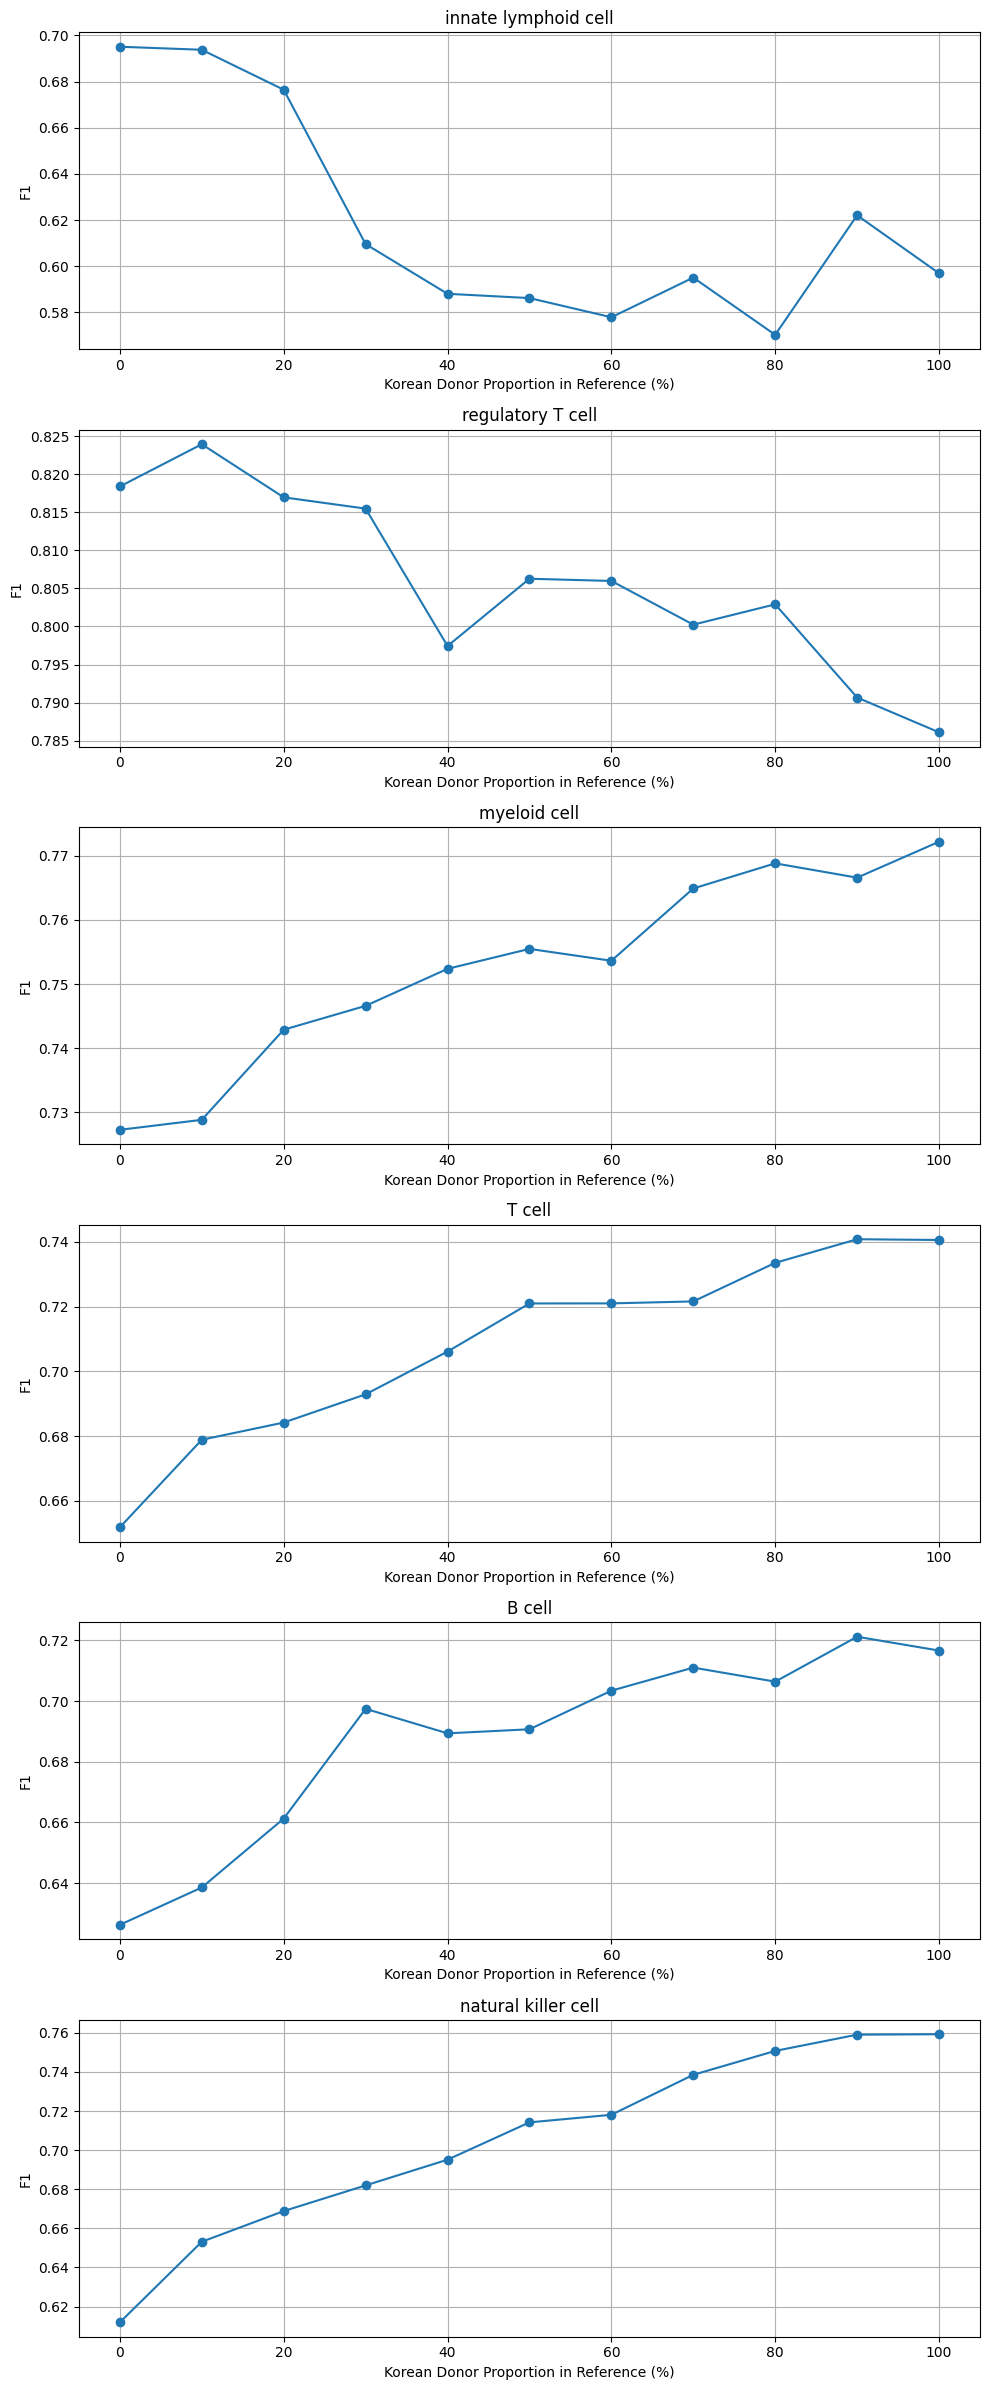

In [ ]:
import matplotlib.pyplot as plt

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'

# Cell types with |ΔF1| > 0.03
important_cells = diff[abs(diff) > 0.03].index.tolist()

fig, axes = plt.subplots(len(important_cells), 1,
                         figsize=(10, 4 * len(important_cells)))

for idx, ct in enumerate(important_cells):
    axes[idx].plot([p * 100 for p in mean_by_cell.columns],
                   mean_by_cell.loc[ct].values, 'o-')
    axes[idx].set_title(ct)
    axes[idx].set_xlabel('Korean Donor Proportion in Reference (%)')
    axes[idx].set_ylabel('F1')
    axes[idx].grid(True)

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/important_celltypes_curve_korean.png', dpi=150)
plt.show()

## 11. Export Sensitive Cell-Type Data

In [ ]:
SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'

important_cells = diff[abs(diff) > 0.03].index.tolist()
df_important    = df_cell[df_cell['cell_type'].isin(important_cells)].copy()

df_important.to_csv(f'{SAVE_DIR}/important_celltypes_korean.csv', index=False)
print('Saved: important_celltypes_korean.csv')
print(f'Cell types included: {important_cells}')
print(df_important.groupby(['cell_type', 'proportion'])['f1'].mean().round(3))

Saved: important_celltypes_korean.csv
Cell types included: ['innate lymphoid cell', 'regulatory T cell', 'myeloid cell', 'T cell', 'B cell', 'natural killer cell']
cell_type          proportion
B cell             0.0           0.626
                   0.1           0.639
                   0.2           0.661
                   0.3           0.697
                   0.4           0.689
                                 ...  
regulatory T cell  0.6           0.806
                   0.7           0.800
                   0.8           0.803
                   0.9           0.791
                   1.0           0.786
Name: f1, Length: 66, dtype: float64


## 12. Heatmap — F1 by Cell Type and Korean Proportion

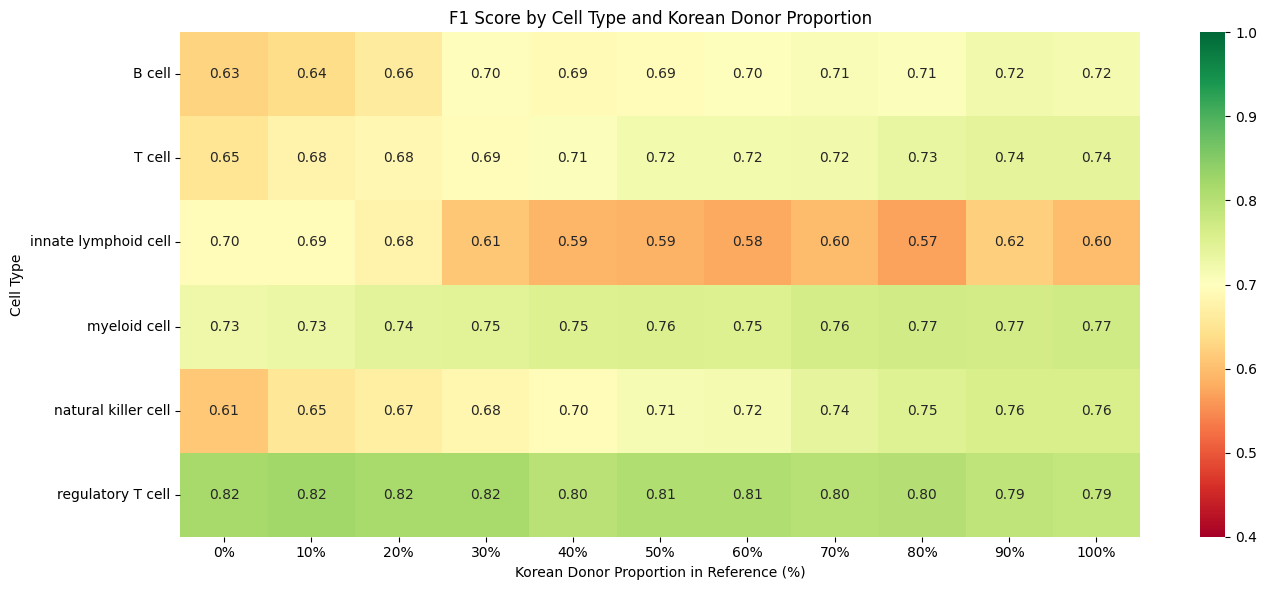

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'

pivot = df_important.groupby(['cell_type', 'proportion'])['f1'].mean().unstack()

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn',
            xticklabels=[f'{int(p * 100)}%' for p in pivot.columns],
            vmin=0.4, vmax=1.0, ax=ax)
ax.set_xlabel('Korean Donor Proportion in Reference (%)')
ax.set_ylabel('Cell Type')
ax.set_title('F1 Score by Cell Type and Korean Donor Proportion')
fig.tight_layout()
fig.savefig(f'{SAVE_DIR}/heatmap_important_celltypes_korean.png', dpi=150)
plt.show()

## 13. Line Chart — F1 by Cell Type and Korean Proportion

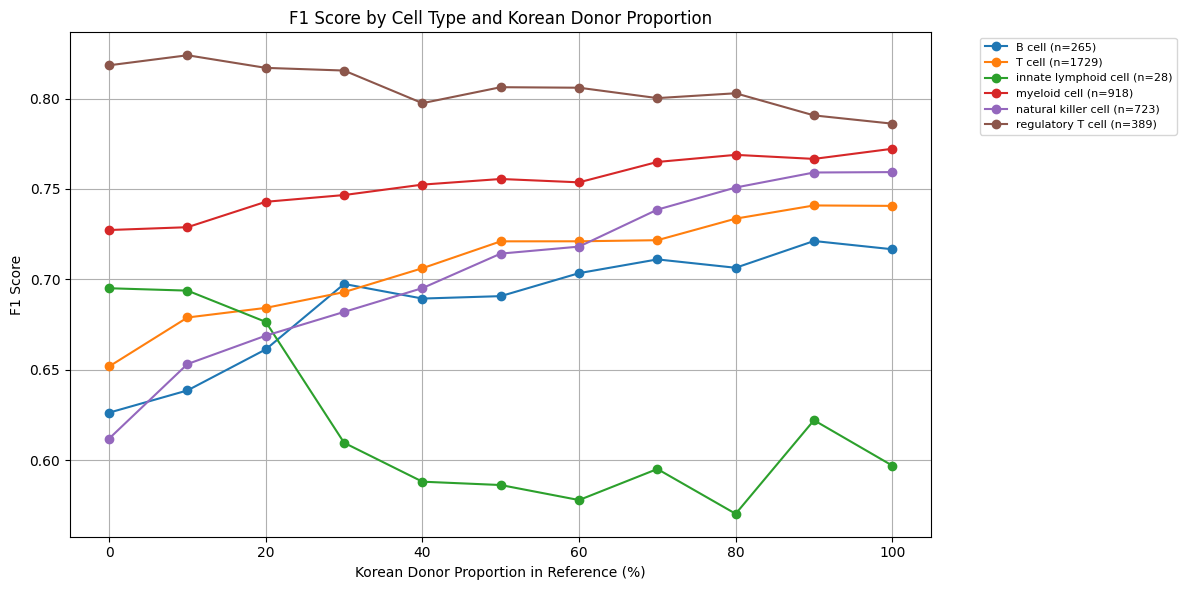

In [ ]:
import matplotlib.pyplot as plt

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/korean'

support_by_cell = df_important.groupby('cell_type')['support'].mean().round(0).astype(int)
pivot           = df_important.groupby(['cell_type', 'proportion'])['f1'].mean().unstack()

fig, ax = plt.subplots(figsize=(12, 6))
for ct in pivot.index:
    ax.plot([p * 100 for p in pivot.columns],
            pivot.loc[ct].values,
            'o-', label=f'{ct} (n={support_by_cell[ct]})', linewidth=1.5)

ax.set_xlabel('Korean Donor Proportion in Reference (%)')
ax.set_ylabel('F1 Score')
ax.set_title('F1 Score by Cell Type and Korean Donor Proportion')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
ax.grid(True)
fig.tight_layout()
fig.savefig(f'{SAVE_DIR}/linechart_important_celltypes_korean.png', dpi=150)
plt.show()